<a href="https://colab.research.google.com/github/allusaatvikacs24-collab/BIS_LAB/blob/main/Particle_Swarm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install numpy matplotlib scikit-learn

Iteration  25 | Best training loss: 0.046113
Iteration  50 | Best training loss: 0.038626
Iteration  75 | Best training loss: 0.036889
Iteration 100 | Best training loss: 0.035466
Iteration 125 | Best training loss: 0.034190
Iteration 150 | Best training loss: 0.032921
Iteration 175 | Best training loss: 0.032219
Iteration 200 | Best training loss: 0.022425
Iteration 225 | Best training loss: 0.014157
Iteration 250 | Best training loss: 0.013434
Iteration 275 | Best training loss: 0.012979
Iteration 300 | Best training loss: 0.012671

========== FINAL RESULTS ==========
Neural network parameters: 43
Best training loss: 0.012671
Test accuracy: 94.74%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.92      0.92      0.92        13
   virginica       0.92      0.92      0.92        13

    accuracy                           0.95        38
   macro avg       0.95      0.95      0.95   

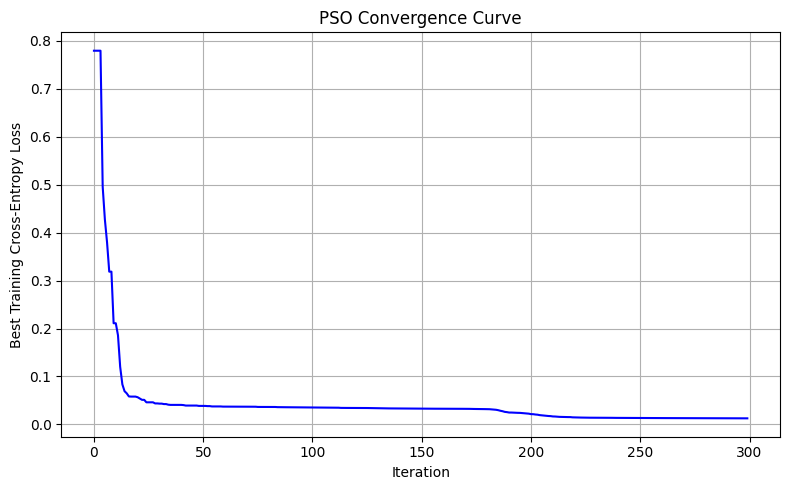

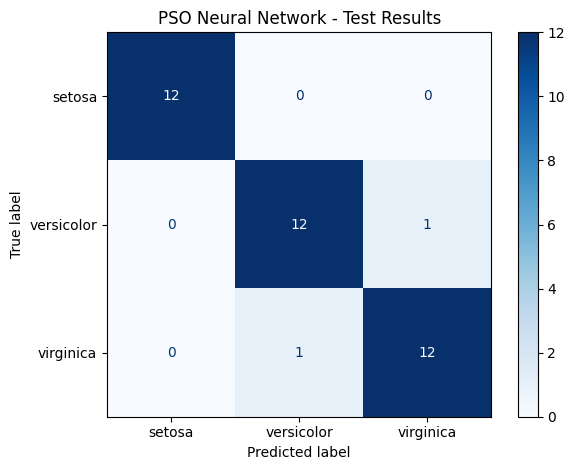

In [2]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =====================================================
# STEP 1: LOAD DATASET
# =====================================================

iris = load_iris()
X = iris.data
y = iris.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Normalize input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# One-hot encode the target classes
num_classes = 3
Y_train = np.eye(num_classes)[y_train]

# =====================================================
# STEP 2: DEFINE NEURAL NETWORK
# Architecture: 4 inputs -> 5 hidden neurons -> 3 outputs
# =====================================================

input_size = 4
hidden_size = 5
output_size = 3

# Total parameters = 4*5 + 5 + 5*3 + 3 = 43
DIM = (
    input_size * hidden_size
    + hidden_size
    + hidden_size * output_size
    + output_size
)

def unpack_weights(position):
    """Convert a particle into neural network weights and biases."""
    i = 0

    W1 = position[i:i + input_size * hidden_size].reshape(
        input_size, hidden_size
    )
    i += input_size * hidden_size

    b1 = position[i:i + hidden_size]
    i += hidden_size

    W2 = position[i:i + hidden_size * output_size].reshape(
        hidden_size, output_size
    )
    i += hidden_size * output_size

    b2 = position[i:i + output_size]

    return W1, b1, W2, b2


def predict_probabilities(X, position):
    """Forward propagation through the neural network."""
    W1, b1, W2, b2 = unpack_weights(position)

    hidden = np.tanh(X @ W1 + b1)
    logits = hidden @ W2 + b2

    # Numerically stable softmax
    logits = logits - np.max(logits, axis=1, keepdims=True)
    exp_logits = np.exp(logits)

    return exp_logits / np.sum(
        exp_logits, axis=1, keepdims=True
    )


# =====================================================
# STEP 3: DEFINE FITNESS FUNCTION
# Minimize cross-entropy classification loss
# =====================================================

def fitness(position):
    probabilities = predict_probabilities(X_train, position)

    epsilon = 1e-12
    loss = -np.mean(
        np.sum(
            Y_train * np.log(probabilities + epsilon),
            axis=1
        )
    )

    return loss


# =====================================================
# STEP 4: INITIALIZE PSO PARAMETERS
# =====================================================

NUM_PARTICLES = 40
MAX_ITERATIONS = 300

W_MAX = 0.9
W_MIN = 0.4

C1 = 1.7  # Cognitive coefficient
C2 = 1.7  # Social coefficient

POSITION_MIN = -3.0
POSITION_MAX = 3.0

VELOCITY_MIN = -0.5
VELOCITY_MAX = 0.5

rng = np.random.default_rng(42)

# Random initial positions and velocities
positions = rng.uniform(
    POSITION_MIN, POSITION_MAX,
    (NUM_PARTICLES, DIM)
)

velocities = rng.uniform(
    VELOCITY_MIN, VELOCITY_MAX,
    (NUM_PARTICLES, DIM)
)

# Personal best positions and their fitness
personal_best_positions = positions.copy()
personal_best_scores = np.array([
    fitness(p) for p in positions
])

# Global best position
best_index = np.argmin(personal_best_scores)

global_best_position = personal_best_positions[
    best_index
].copy()

global_best_score = personal_best_scores[best_index]

best_history = []

# =====================================================
# STEP 5: RUN PARTICLE SWARM OPTIMIZATION
# =====================================================

for iteration in range(MAX_ITERATIONS):

    # Linearly decrease inertia weight
    w = W_MAX - (
        (W_MAX - W_MIN) * iteration / MAX_ITERATIONS
    )

    r1 = rng.random((NUM_PARTICLES, DIM))
    r2 = rng.random((NUM_PARTICLES, DIM))

    # Update particle velocities
    velocities = (
        w * velocities
        + C1 * r1 * (
            personal_best_positions - positions
        )
        + C2 * r2 * (
            global_best_position - positions
        )
    )

    # Limit velocity
    velocities = np.clip(
        velocities, VELOCITY_MIN, VELOCITY_MAX
    )

    # Update particle positions
    positions = positions + velocities

    positions = np.clip(
        positions, POSITION_MIN, POSITION_MAX
    )

    # Evaluate fitness for every particle
    current_scores = np.array([
        fitness(p) for p in positions
    ])

    # Update personal bests
    improved = current_scores < personal_best_scores

    personal_best_positions[improved] = positions[improved]
    personal_best_scores[improved] = current_scores[improved]

    # Update global best
    best_index = np.argmin(personal_best_scores)

    if personal_best_scores[best_index] < global_best_score:
        global_best_score = personal_best_scores[best_index]
        global_best_position = personal_best_positions[
            best_index
        ].copy()

    best_history.append(global_best_score)

    if (iteration + 1) % 25 == 0:
        print(
            f"Iteration {iteration + 1:3d} | "
            f"Best training loss: {global_best_score:.6f}"
        )

# =====================================================
# STEP 6: EVALUATE THE OPTIMIZED NEURAL NETWORK
# =====================================================

test_probabilities = predict_probabilities(
    X_test, global_best_position
)

y_pred = np.argmax(test_probabilities, axis=1)

accuracy = accuracy_score(y_test, y_pred)

print("\n========== FINAL RESULTS ==========")
print("Neural network parameters:", DIM)
print(f"Best training loss: {global_best_score:.6f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# =====================================================
# STEP 7: PLOT CONVERGENCE AND CONFUSION MATRIX
# =====================================================

plt.figure(figsize=(8, 5))
plt.plot(best_history, color="blue")
plt.title("PSO Convergence Curve")
plt.xlabel("Iteration")
plt.ylabel("Best Training Cross-Entropy Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
)

plt.title("PSO Neural Network - Test Results")
plt.tight_layout()
plt.show()
